## This jupter notebook contains code for gradient descent calculated in code.

## The code below does the following tasks we did in manual gradiant descent calculation.
1. Compute the predicted values ŷ for each data point using the current values of m and b.
2. Derive the gradient of the Mean Squared Error (MSE) cost function J(m,b).
3. Iteratively update m and b using Gradient Descent.
4. Describe the trend in the values of m and b. Are they moving in a direction that reduces the error?
5. Visualization

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime
X = np.array([[1.0, 3.0],[4.0, 10.0]], dtype=float)
y = np.array([5.0, 6.0], dtype=float)
initial_m = np.array([-1.0, 2.0], dtype=float)
initial_b = np.array([1.0, 1.0], dtype=float)
alpha = 0.01

print("Input data(X) as matrix:\n", X)
print("Target output(y) as vector:\n", y)
print("Initial m as vector:\n", initial_m)
print("Initial b also as vector:\n", initial_b)

Input data(X) as matrix:
 [[ 1.  3.]
 [ 4. 10.]]
Target output(y) as vector:
 [5. 6.]
Initial m as vector:
 [-1.  2.]
Initial b also as vector:
 [1. 1.]


In [3]:
def calculate_prediction(X, theta):
    # This function predicting the output using matrix multiplication and vector addition
    # Here "theta" is parameter vector
    # theta = [m1,m2,b]^T
    vector_m = theta[:2].reshape(2,1)
    ones_vector = np.ones((X.shape[0], 1))
    vector_b = ones_vector * theta[2]
    y_hat = np.matmul(X, vector_m) + vector_b
    return y_hat
    
def mse_cost_function(theta, X, y):
    # Here MSE is calculated using matrix transpose multiplication
    # MSE or J = 1/N(e^Te) where "e" is error vector calculated
    # (y^(i)-y(i))
    N = y.shape[0]
    error_vector = calculate_prediction(X, theta) - y.reshape(-1,1)
    squared_error_matrix = np.matmul(error_vector.T, error_vector)
    cost = (1.0 / N) * squared_error_matrix[0, 0]
    return cost
initial_theta = np.array([-1.0, 2.0, 1.0], dtype=float)
initial_prediction = calculate_prediction(X, initial_theta)
initial_cost = mse_cost_function(initial_theta, X,y)

print(f"Initial prediction(Iteration 0) (shape: {initial_prediction.shape}:\n",initial_prediction)
print(f"\nInitial MSE(cost: {initial_cost:.4f}")
    
    
    
    

Initial prediction(Iteration 0) (shape: (2, 1):
 [[ 6.]
 [17.]]

Initial MSE(cost: 61.0000


In [4]:
def calculate_derivative(cost_function, theta, X, y):
    epsilon = np.sqrt(np.finfo(float).eps)
    grad = approx_fprime(theta, cost_function, epsilon, X, y)
    return grad
initial_gradients = calculate_derivative(mse_cost_function, initial_theta, X, y)
print("Initial gradient vector:\n", initial_gradients)
    
    
    

Initial gradient vector:
 [ 45.         113.00000095  12.        ]


In [15]:
epochs = 30
alpha = 0.01
m_history = []
b_history = []
cost_history = []

current_theta = np.array([initial_m[0], initial_m[1],initial_b[0]], dtype=float)
print(f"{'Epoch':<6}{'m1':<9}{'m2':<9}{'b':<8}{'MSE Cost':<10}{'y_hat1':<9}{'y1':<5}{'y_hat2':<9}{'y2':<5}")

print("-" * 70)
for epoch in range(epochs + 1):
    
    m_vector = current_theta[:2].reshape(2, 1)
    b_vector = np.ones((X.shape[0], 1)) * current_theta[2]

    preds = calculate_prediction(X, current_theta)
    cost = mse_cost_function(current_theta, X, y)

    # Record historical metrics plotting
    m_history.append(m_vector.copy())
    b_history.append(current_theta[2])
    cost_history.append(cost)
    grads = calculate_derivative(mse_cost_function, current_theta, X, y)
    y_hat_1 = preds.ravel()[0]
    y_hat_2 = preds.ravel()[1]
    if epoch <= epochs:
        print(
        f"{epoch:<6}{m_vector[0, 0]:<9.4f}"
        f"{m_vector[1, 0]:<9.4f}{current_theta[2]:<8.4f}"
        f"{cost:<10.4f}{y_hat_1:<9.4f}{y.ravel()[0]:<5.1f}"
        f"{y_hat_2:<9.4f}{y.ravel()[1]:<5.1f}")
        
    if epoch < epochs:
        # Parameter update formula: theta = theta - (alpha * grad)
        current_theta = current_theta - (alpha * grads)
        
m_history = np.array(m_history).squeeze()
b_history = np.array(b_history)
cost_history = np.array(cost_history)

print("\n" + "=" * 50)
print("FINAL OPTIMIZED MODEL PARAMETERS:")
print(f"Optimal m1: {current_theta[0]:.4f}")
print(f"Optimal m2: {current_theta[1]:.4f}")
print(f"Optimal b:  {current_theta[2]:.4f}")
print(f"Final MSE Cost: {cost_history[-1]:.6f}")

final_predictions = calculate_prediction(X, current_theta)
print("\nFINAL PREDICTIONS VS TRUTH:")
print("Predicted y_hat:\n", final_predictions)
print("Actual y:\n", y)


Epoch m1       m2       b       MSE Cost  y_hat1   y1   y_hat2   y2   
----------------------------------------------------------------------
0     -1.0000  2.0000   1.0000  61.0000   6.0000   5.0  17.0000  6.0  
1     -1.4500  0.8700   0.8800  6.8450    2.0400   5.0  3.7800   6.0  
2     -1.3316  1.1808   0.9318  2.7238    3.1426   5.0  7.4134   6.0  
3     -1.3696  1.0952   0.9362  2.3904    2.8522   5.0  6.4098   6.0  
4     -1.3645  1.1186   0.9536  2.3440    2.9450   5.0  6.6821   6.0  
5     -1.3712  1.1121   0.9673  2.3195    2.9324   5.0  6.6033   6.0  
6     -1.3747  1.1138   0.9820  2.2969    2.9487   5.0  6.6211   6.0  
7     -1.3790  1.1132   0.9963  2.2746    2.9569   5.0  6.6124   6.0  
8     -1.3831  1.1133   1.0106  2.2525    2.9673   5.0  6.6110   6.0  
9     -1.3872  1.1131   1.0248  2.2307    2.9771   5.0  6.6076   6.0  
10    -1.3912  1.1131   1.0390  2.2090    2.9870   5.0  6.6047   6.0  
11    -1.3953  1.1130   1.0531  2.1876    2.9967   5.0  6.6018   6.0  
12    

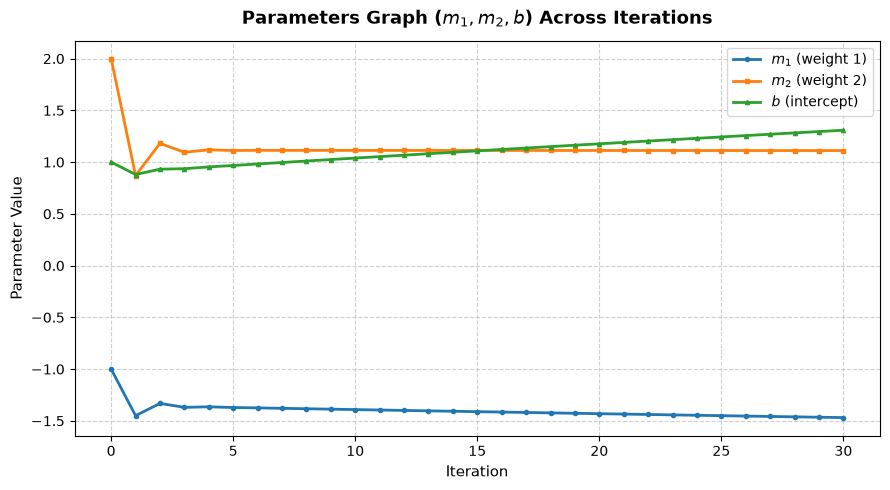

In [16]:
# Converting tracking lists to NumPy arrays
m_history_arr = np.array(m_history)  # Shape: (epochs + 1, 2)
b_history_arr = np.array(b_history)  # Shape: (epochs + 1,)
iterations_range = np.arange(len(b_history_arr))

plt.figure(figsize=(9, 5))

# Plot m1, m2, and b
plt.plot(iterations_range, m_history_arr[:, 0], label=r'$m_1$ (weight 1)', color='#1f77b4', linewidth=2, marker='o', markersize=3)
plt.plot(iterations_range, m_history_arr[:, 1], label=r'$m_2$ (weight 2)', color='#ff7f0e', linewidth=2, marker='s', markersize=3)
plt.plot(iterations_range, b_history_arr, label=r'$b$ (intercept)', color='#2ca02c', linewidth=2, marker='^', markersize=3)

# Formatting labels and title
plt.title("Parameters Graph ($m_1, m_2, b$) Across Iterations", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Parameter Value", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

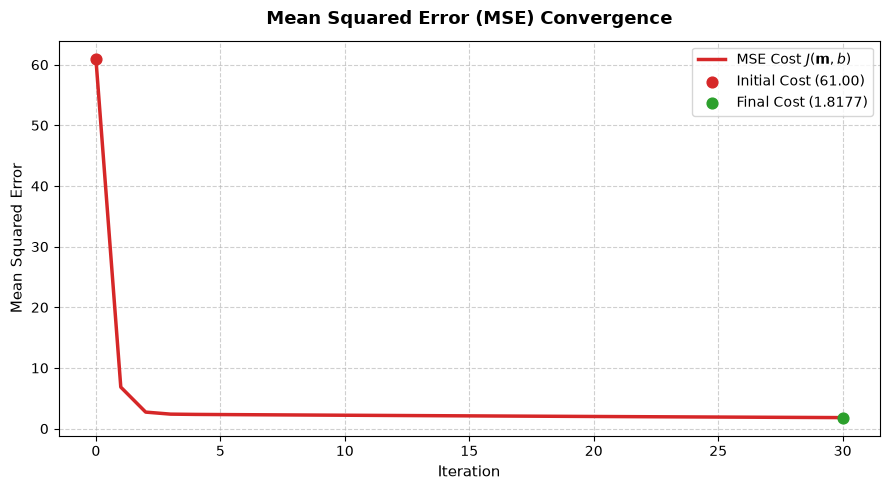

In [17]:
cost_history_arr = np.array(cost_history)

plt.figure(figsize=(9, 5))

# Plot MSE cost change
plt.plot(iterations_range, cost_history_arr, label=r'MSE Cost $J(\mathbf{m}, b)$', color='#d62728', linewidth=2.5)

# Highlighting starting cost and final cost with points
plt.scatter([0], [cost_history_arr[0]], color='#d62728', s=60, zorder=5, label=f'Initial Cost ({cost_history_arr[0]:.2f})')
plt.scatter([len(cost_history_arr)-1], [cost_history_arr[-1]], color='#2ca02c', s=60, zorder=5, label=f'Final Cost ({cost_history_arr[-1]:.4f})')

# Formatting labels and title
plt.title("Mean Squared Error (MSE) Convergence", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Iteration", fontsize=11)
plt.ylabel("Mean Squared Error", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()